# 03 · Week 3: the closed loop between the fly brain and an LLM
A connectome-constrained LIF simulation with trained readouts, wired to a language model:
1. **Words in:** 5 stimuli back to back (500 ms each) drive sensory neurons of one continuous simulation.
2. **Fly → LLM:** the word readout decodes each 500 ms window; decoded words become a first-person sentence ("I smell vinegar. ... What should I do?").
3. **LLM → fly:** the LLM picks one of five actions; the action is played as a spike code on Johnston's organ (JO) hearing neurons.
4. **Read back:** a readout of descending neurons (DNs) only decodes the action.

Brain: Week 2 calibrated MaleCNS + presynaptic modulation of sensory terminals (K = 0.05) + right-JO mirror. Loads saved results only.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
R = ROOT / 'results'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
L = R/'loop'

## Day 1: carry-over between words
40 episodes of 5 words, spacing 0, 250 or 500 ms. The original calibrated model (left) vs the presynaptic-modulation model (right): with presynaptic inhibition of sensory terminals, a readout trained on isolated words reads episodes perfectly.

In [2]:
a = pd.read_csv(L/'w3d1_carryover.csv'); b = pd.read_csv(L/'w3d1_carryover_presyn0.05.csv')
show = lambda d: d[d.readout.isin(['isolated', 'episode-trained 5-fold'])].pivot_table(index=['readout', 'features'], columns='gap_ms', values='acc')
print('calibrated (Week 2)'); display(show(a).round(3)); print('+ presynaptic modulation K=0.05')
display(b[['readout', 'features', 'acc_test_eps']].round(3))

calibrated (Week 2)


gap_ms                             0     250    500
readout                features                    
episode-trained 5-fold all       1.000  1.00  1.000
                       motor     0.915  0.90  0.915
isolated               all       0.955  0.96  0.955
                       motor     0.825  0.82  0.815

+ presynaptic modulation K=0.05


,readout,features,acc_test_eps
0,isolated,all,1.000
1,episode-trained,all,1.000
2,episode-trained 5-fold,all,1.000
3,isolated,motor,0.900
4,episode-trained,motor,0.933
5,episode-trained 5-fold,motor,0.915


## Day 3-4: action codes on the hearing neurons
Five codes on JO-A/JO-B neurons (left, right, both, pulsed). Day 4 test: each code played after a 5-word episode, 37 held-out trials.

In [3]:
sc = json.load(open(L/'w3d4_score.json'))
pd.DataFrame([dict(readout=k, correct=f"{v['correct']}/{v['n']}", neurons_that_fire=v['features_active'], errors='; '.join(v['errors']))
              for k, v in sc.items() if isinstance(v, dict)])

,readout,correct,neurons_that_fire,errors
0,real/DN,37/37,445,
1,real/all non-sensory,37/37,3361,
2,shuffle/DN,36/37,24,umami+co2+dry+bitter+wind: turn right -> none
3,shuffle/all non-sensory,37/37,1049,


The shuffled brain reads the codes back almost as well (36/37), but through 24 DNs instead of 445: the real wiring routes the hearing input to many more descending neurons. Reading back a stimulus you injected yourself works with almost any wiring.

## Day 5-6: the full loop
Three rounds in one 10.5 s simulation. `w3d6` runs use an offline rule-based stand-in for the LLM; `w3d6c` runs call Claude (claude-sonnet-5-5) live through the Claude Code CLI.

In [4]:
rows = []
for tag, llm in [('w3d6', 'offline stand-in'), ('w3d6c', 'Claude')]:
    for f in sorted(L.glob(f'{tag}_loop_*[0-9].json')):
        d = json.load(open(f))
        rows.append(dict(llm=llm, run=f"{d['cfg']} {d['seed']}", words=f"{sum(r['words_correct'] for r in d['rounds'])}/15",
                         actions=' / '.join(r['action'] for r in d['rounds']),
                         read_back=f"{sum(r['action_ok'] for r in d['rounds'])}/3",
                         confidence=' '.join(f"{r['action_p']:.2f}" for r in d['rounds'])))
pd.DataFrame(rows)

,llm,run,words,actions,read_back,confidence
0,offline stand-in,real 4000,15/15,turn left / go forward / eat,3/3,0.98 1.00 0.97
1,offline stand-in,real 4001,15/15,turn left / turn right / turn right,3/3,0.97 0.87 0.84
2,offline stand-in,real 4002,15/15,turn left / stop / eat,3/3,0.97 0.97 0.99
3,offline stand-in,shuffle 4000,15/15,turn left / go forward / eat,3/3,0.81 0.88 0.93
4,Claude,real 4000,15/15,turn left / go forward / eat,3/3,0.98 1.00 0.97
5,Claude,real 4001,15/15,stop / eat / eat,3/3,0.96 0.99 0.99
6,Claude,real 4002,15/15,turn left / turn left / eat,3/3,0.97 0.99 0.99
7,Claude,shuffle 4000,15/15,turn left / turn left / eat,3/3,0.81 0.87 0.91


round 1: 'I smell vinegar. I smell ripe fruit. I taste sugar. It feels hot. Something is looming toward me. What should I do?' -> Claude: 'turn left' -> DNs read turn left (0.98)
round 2: 'I feel wind. It feels cold. The air feels humid. I hear a sound. I smell ripe fruit. What should I do?' -> Claude: 'go forward' -> DNs read go forward (1.00)
round 3: 'I smell ripe fruit. I taste something savory. I feel wind. I taste water. It feels cold. What should I do?' -> Claude: 'eat' -> DNs read eat (0.97)


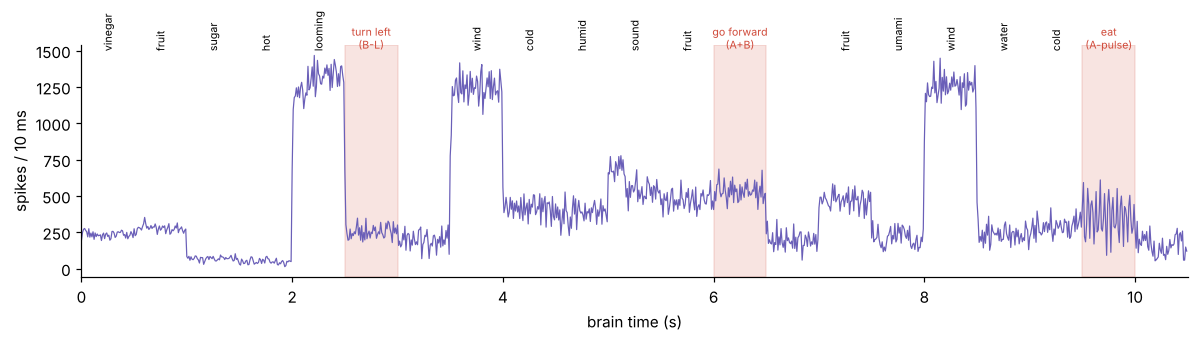

In [5]:
d = json.load(open(L/'w3d6c_loop_real_4000.json'))
pop = np.array(d['pop_10ms']); t = np.arange(len(pop)) / 100
fig, ax = plt.subplots(figsize=(11, 3.2)); ax.plot(t, pop, color='#6a5fb8', lw=.8)
for r in d['rounds']:
    for k, w in enumerate(r['decoded']):
        ax.text(r['t_start'] + k*.5 + .25, pop.max()*1.02, w, ha='center', fontsize=7, rotation=90, va='bottom')
    ax.axvspan(r['t_words'], r['t_words'] + .5, color='#d04a3a', alpha=.15)
    ax.text(r['t_words'] + .25, pop.max()*1.02, f"{r['action']}\n({r['code']})", ha='center', fontsize=7, color='#d04a3a', va='bottom')
ax.set(xlabel='brain time (s)', ylabel='spikes / 10 ms', xlim=(0, d['t_total'])); plt.tight_layout()
for r in d['rounds']: print(f"round {r['round']}: {r['prompt']!r} -> Claude: {r['llm_raw']!r} -> DNs read {r['action_decoded']} ({r['action_p']:.2f})")

## What is deterministic, what is learned
- **Deterministic:** connectome weights, LIF equations, the Week 2 calibration, presynaptic modulation, the right-JO mirror, stimulus sets and rates, the action codes.
- **Learned:** only the two linear readouts (words: all non-sensory neurons; actions: DNs only). The connectome is never trained.
- **Not deterministic:** the LLM. The identical round-1 sentence got "turn left" three times and "stop" once from Claude.
- **What the shuffled brain also does:** 15/15 words and 3/3 actions in the loop, with lower action confidence (0.81-0.93).

Playback: `artifact/loop/index.html` (split-screen player) and `results/figures/loop_demo.mp4`.